In [1]:

import pandas as pd

# Repositorio público del Laboratorio 4
base_url = "https://raw.githubusercontent.com/Brianrp19/laboratorio4-mineria-datos/main/datos/origen/"

# Archivos originales del Proyecto 1
archivos = [
    "Album", "Artist", "Customer", "Employee",
    "Genre", "Invoice", "InvoiceLine",
    "MediaType", "Playlist", "PlaylistTrack", "Track"
]

# Leer los CSV directamente desde GitHub
tablas = {}

for nombre in archivos:
    url = base_url + nombre + ".csv"
    tablas[nombre] = pd.read_csv(url)
    print(f"{nombre}: {tablas[nombre].shape[0]} filas y {tablas[nombre].shape[1]} columnas")


Album: 347 filas y 3 columnas
Artist: 275 filas y 2 columnas
Customer: 59 filas y 13 columnas
Employee: 8 filas y 15 columnas
Genre: 25 filas y 2 columnas
Invoice: 412 filas y 9 columnas
InvoiceLine: 2240 filas y 5 columnas
MediaType: 5 filas y 2 columnas
Playlist: 18 filas y 2 columnas
PlaylistTrack: 8715 filas y 2 columnas
Track: 3503 filas y 9 columnas


# Laboratorio 4 — Minería de Datos

## Análisis Exploratorio de Datos (EDA)

**Dataset:** Chinook — Proyecto 1

**Objetivo:** Analizar la estructura, calidad y comportamiento de los datos originales de Chinook utilizando Python en Google Colab.

Los archivos CSV se cargan directamente desde el repositorio público de GitHub, sin modificar los datos originales.

### Etapa 1. Exploración inicial de los datos

In [2]:

# Revisar la calidad inicial de las 11 tablas

for nombre, df in tablas.items():
    print(f"\n--- {nombre} ---")
    print("Filas:", df.shape[0])
    print("Columnas:", df.shape[1])
    print("Valores nulos:", df.isnull().sum().sum())
    print("Filas duplicadas:", df.duplicated().sum())



--- Album ---
Filas: 347
Columnas: 3
Valores nulos: 0
Filas duplicadas: 0

--- Artist ---
Filas: 275
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Customer ---
Filas: 59
Columnas: 13
Valores nulos: 130
Filas duplicadas: 0

--- Employee ---
Filas: 8
Columnas: 15
Valores nulos: 1
Filas duplicadas: 0

--- Genre ---
Filas: 25
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Invoice ---
Filas: 412
Columnas: 9
Valores nulos: 230
Filas duplicadas: 0

--- InvoiceLine ---
Filas: 2240
Columnas: 5
Valores nulos: 0
Filas duplicadas: 0

--- MediaType ---
Filas: 5
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Playlist ---
Filas: 18
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- PlaylistTrack ---
Filas: 8715
Columnas: 2
Valores nulos: 0
Filas duplicadas: 0

--- Track ---
Filas: 3503
Columnas: 9
Valores nulos: 978
Filas duplicadas: 0


In [3]:

# Identificar las columnas que contienen valores nulos

for nombre in ["Customer", "Employee", "Invoice", "Track"]:
    df = tablas[nombre]

    resumen = pd.DataFrame({
        "Valores nulos": df.isnull().sum(),
        "Porcentaje (%)": (df.isnull().mean() * 100).round(2)
    })

    print(f"\n--- {nombre} ---")

    display(resumen[resumen["Valores nulos"] > 0])



--- Customer ---


,Valores nulos,Porcentaje (%)
Company,49,83.05
State,29,49.15
PostalCode,4,6.78
Phone,1,1.69
Fax,47,79.66



--- Employee ---


,Valores nulos,Porcentaje (%)
ReportsTo,1,12.5



--- Invoice ---


,Valores nulos,Porcentaje (%)
BillingState,202,49.03
BillingPostalCode,28,6.80



--- Track ---


,Valores nulos,Porcentaje (%)
Composer,978,27.92


In [5]:

# Verificar las relaciones entre las tablas

relaciones = [
    ("InvoiceLine", "InvoiceId", "Invoice", "InvoiceId"),
    ("InvoiceLine", "TrackId", "Track", "TrackId"),
    ("Invoice", "CustomerId", "Customer", "CustomerId"),
    ("Track", "GenreId", "Genre", "GenreId")
]

for origen, columna_origen, destino, columna_destino in relaciones:
    # Identificar registros sin correspondencia
    sin_relacion = ~tablas[origen][columna_origen].isin(
        tablas[destino][columna_destino]
    )

    # Comprobar identificadores repetidos en la tabla destino
    repetidos = tablas[destino][columna_destino].duplicated().sum()

    print(f"\n{origen} -> {destino}")
    print("Registros sin relación:", sin_relacion.sum())
    print("Identificadores repetidos en destino:", repetidos)



InvoiceLine -> Invoice
Registros sin relación: 0
Identificadores repetidos en destino: 0

InvoiceLine -> Track
Registros sin relación: 0
Identificadores repetidos en destino: 0

Invoice -> Customer
Registros sin relación: 0
Identificadores repetidos en destino: 0

Track -> Genre
Registros sin relación: 0
Identificadores repetidos en destino: 0


In [6]:

# Construcción del dataset analítico de ventas

ventas = tablas["InvoiceLine"].copy()

# Agregar información de las facturas
ventas = ventas.merge(
    tablas["Invoice"][["InvoiceId", "CustomerId", "InvoiceDate", "BillingCountry"]],
    on="InvoiceId",
    how="left",
    validate="many_to_one"
)

# Agregar información de las canciones
canciones = tablas["Track"][["TrackId", "Name", "GenreId", "Milliseconds"]].copy()
canciones = canciones.rename(columns={"Name": "Cancion"})

ventas = ventas.merge(
    canciones,
    on="TrackId",
    how="left",
    validate="many_to_one"
)

# Agregar el género musical
generos = tablas["Genre"][["GenreId", "Name"]].copy()
generos = generos.rename(columns={"Name": "Genero"})

ventas = ventas.merge(
    generos,
    on="GenreId",
    how="left",
    validate="many_to_one"
)

# Agregar el país del cliente
ventas = ventas.merge(
    tablas["Customer"][["CustomerId", "Country"]],
    on="CustomerId",
    how="left",
    validate="many_to_one"
)

# Convertir la fecha
ventas["InvoiceDate"] = pd.to_datetime(ventas["InvoiceDate"])

# Calcular el importe de cada línea de venta
ventas["ImporteLinea"] = ventas["UnitPrice"] * ventas["Quantity"]

# Comprobar que no perdimos ni multiplicamos registros
assert len(ventas) == len(tablas["InvoiceLine"])

print("Filas del dataset:", ventas.shape[0])
print("Columnas del dataset:", ventas.shape[1])
print("Facturas diferentes:", ventas["InvoiceId"].nunique())
print("Clientes diferentes:", ventas["CustomerId"].nunique())

display(ventas.head())


Filas del dataset: 2240
Columnas del dataset: 14
Facturas diferentes: 412
Clientes diferentes: 59


,InvoiceLineId,InvoiceId,TrackId,UnitPrice,Quantity,CustomerId,InvoiceDate,BillingCountry,Cancion,GenreId,Milliseconds,Genero,Country,ImporteLinea
0,1,1,2,0.99,1,2,2009-01-01,Germany,Balls to the Wall,1,342562,Rock,Germany,0.99
1,2,1,4,0.99,1,2,2009-01-01,Germany,Restless and Wild,1,252051,Rock,Germany,0.99
2,3,2,6,0.99,1,4,2009-01-02,Norway,Put The Finger On You,1,205662,Rock,Norway,0.99
3,4,2,8,0.99,1,4,2009-01-02,Norway,Inject The Venom,1,210834,Rock,Norway,0.99
4,5,2,10,0.99,1,4,2009-01-02,Norway,Evil Walks,1,263497,Rock,Norway,0.99


In [7]:

# Validación del dataset analítico

print("Valores nulos por columna:")
print(ventas.isnull().sum())

print("\nLíneas de venta duplicadas:")
print(ventas["InvoiceLineId"].duplicated().sum())

# Comprobar los importes de las ventas
total_calculado = ventas["ImporteLinea"].sum()
total_facturas = tablas["Invoice"]["Total"].sum()

print("\nTotal calculado:", round(total_calculado, 2))
print("Total registrado en facturas:", round(total_facturas, 2))
print("Diferencia:", round(total_calculado - total_facturas, 2))

# Estadísticas descriptivas
display(
    ventas[["UnitPrice", "Quantity", "Milliseconds", "ImporteLinea"]]
    .describe()
    .round(2)
)


Valores nulos por columna:
InvoiceLineId     0
InvoiceId         0
TrackId           0
UnitPrice         0
Quantity          0
CustomerId        0
InvoiceDate       0
BillingCountry    0
Cancion           0
GenreId           0
Milliseconds      0
Genero            0
Country           0
ImporteLinea      0
dtype: int64

Líneas de venta duplicadas:
0

Total calculado: 2328.6
Total registrado en facturas: 2328.6
Diferencia: 0.0


,UnitPrice,Quantity,Milliseconds,ImporteLinea
count,2240.00,2240.0,2240.00,2240.00
mean,1.04,1.0,375435.99,1.04
std,0.22,0.0,507221.98,0.22
min,0.99,1.0,6373.00,0.99
25%,0.99,1.0,205981.50,0.99
50%,0.99,1.0,256443.50,0.99
75%,0.99,1.0,321136.00,0.99
max,1.99,1.0,5286953.00,1.99



## Etapa 2 — Calidad y tratamiento de datos
**Responsable:** Cristopher

En esta etapa se analizan los valores faltantes del conjunto
de datos, se renombran las columnas a español y se crean
funciones para tratar información incompleta.

Los archivos originales no se modifican.


In [13]:

# Crear una copia para conservar el dataset original
ventas_tratadas = ventas.copy()

columnas_espanol = {
    "InvoiceLineId": "IdLineaFactura",
    "InvoiceId": "IdFactura",
    "TrackId": "IdCancion",
    "UnitPrice": "PrecioUnitario",
    "Quantity": "Cantidad",
    "CustomerId": "IdCliente",
    "InvoiceDate": "FechaFactura",
    "BillingCountry": "PaisFacturacion",
    "GenreId": "IdGenero",
    "Milliseconds": "DuracionMilisegundos",
    "Country": "PaisCliente"
}

ventas_tratadas.rename(
    columns=columnas_espanol,
    inplace=True
)

print("Columnas del dataset:")
print(ventas_tratadas.columns.tolist())

display(ventas_tratadas.head())


Columnas del dataset:
['IdLineaFactura', 'IdFactura', 'IdCancion', 'PrecioUnitario', 'Cantidad', 'IdCliente', 'FechaFactura', 'PaisFacturacion', 'Cancion', 'IdGenero', 'DuracionMilisegundos', 'Genero', 'PaisCliente', 'ImporteLinea']


,IdLineaFactura,IdFactura,IdCancion,PrecioUnitario,Cantidad,IdCliente,FechaFactura,PaisFacturacion,Cancion,IdGenero,DuracionMilisegundos,Genero,PaisCliente,ImporteLinea
0,1,1,2,0.99,1,2,2009-01-01,Germany,Balls to the Wall,1,342562,Rock,Germany,0.99
1,2,1,4,0.99,1,2,2009-01-01,Germany,Restless and Wild,1,252051,Rock,Germany,0.99
2,3,2,6,0.99,1,4,2009-01-02,Norway,Put The Finger On You,1,205662,Rock,Norway,0.99
3,4,2,8,0.99,1,4,2009-01-02,Norway,Inject The Venom,1,210834,Rock,Norway,0.99
4,5,2,10,0.99,1,4,2009-01-02,Norway,Evil Walks,1,263497,Rock,Norway,0.99


In [14]:

import pandas as pd

# Analizar los nulos del dataset de ventas
resumen_ventas = pd.DataFrame({
    "Nulos": ventas_tratadas.isna().sum(),
    "Porcentaje": (
        ventas_tratadas.isna().mean() * 100
    ).round(2)
})

print("Valores nulos en ventas:")
display(resumen_ventas)

# Analizar las columnas con nulos en los CSV originales
for nombre, df in tablas.items():
    nulos = df.isna().sum()
    nulos = nulos[nulos > 0]

    if not nulos.empty:
        print(f"\nTabla: {nombre}")
        display(pd.DataFrame({
            "Nulos": nulos,
            "Porcentaje": (
                nulos / len(df) * 100
            ).round(2)
        }))


Valores nulos en ventas:


,Nulos,Porcentaje
IdLineaFactura,0,0.0
IdFactura,0,0.0
IdCancion,0,0.0
PrecioUnitario,0,0.0
Cantidad,0,0.0
IdCliente,0,0.0
FechaFactura,0,0.0
PaisFacturacion,0,0.0
Cancion,0,0.0
IdGenero,0,0.0



Tabla: Customer


,Nulos,Porcentaje
Company,49,83.05
State,29,49.15
PostalCode,4,6.78
Phone,1,1.69
Fax,47,79.66



Tabla: Employee


,Nulos,Porcentaje
ReportsTo,1,12.5



Tabla: Invoice


,Nulos,Porcentaje
BillingState,202,49.03
BillingPostalCode,28,6.80



Tabla: Track


,Nulos,Porcentaje
Composer,978,27.92


In [15]:

def imputar_categorica(df, columna, valor="No informado"):
    """Rellena valores faltantes de una columna categórica."""
    resultado = df.copy()
    resultado[columna] = resultado[columna].fillna(valor)
    return resultado


def imputar_numerica_mediana(df, columna):
    """Rellena valores numéricos faltantes con la mediana."""
    resultado = df.copy()
    mediana = resultado[columna].median()
    resultado[columna] = resultado[columna].fillna(mediana)
    return resultado


# Aplicar imputación sobre una columna original con nulos
tracks_tratados = imputar_categorica(
    tablas["Track"],
    "Composer"
)

print("Nulos originales en Composer:",
      tablas["Track"]["Composer"].isna().sum())

print("Nulos después de imputar:",
      tracks_tratados["Composer"].isna().sum())


Nulos originales en Composer: 978
Nulos después de imputar: 0


In [16]:

# Verificar que no se perdieron registros
assert len(ventas_tratadas) == len(ventas)

# Verificar que los importes no cambiaron
assert abs(
    ventas_tratadas["ImporteLinea"].sum()
    - ventas["ImporteLinea"].sum()
) < 0.000001

# Confirmar que el dataset analítico no contiene nulos
assert ventas_tratadas.isna().sum().sum() == 0

print("Validaciones completadas correctamente.")
print("Registros conservados:", len(ventas_tratadas))
print("Total de ventas:", round(
    ventas_tratadas["ImporteLinea"].sum(), 2
))


Validaciones completadas correctamente.
Registros conservados: 2240
Total de ventas: 2328.6



## Etapa 2.1 — Visualización de valores faltantes y atípicos

En esta sección se representan gráficamente los valores
faltantes de los archivos originales y se analizan posibles
valores atípicos en las variables numéricas del conjunto
de ventas.

El objetivo es identificar problemas de calidad sin eliminar
información válida de manera innecesaria.


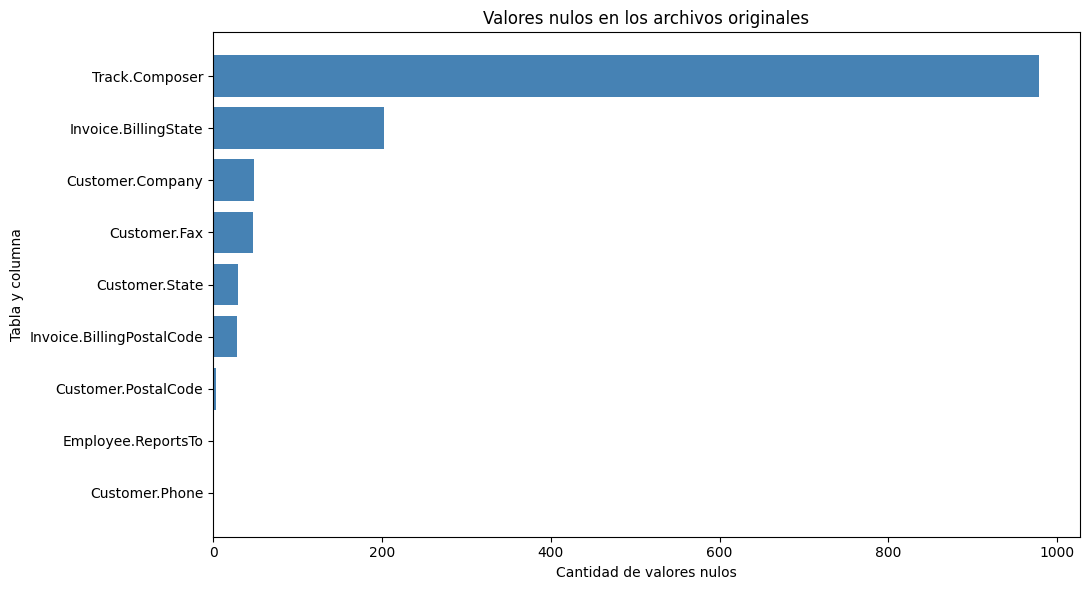

In [17]:

import matplotlib.pyplot as plt
import pandas as pd

# Reunir los valores nulos de los CSV originales
datos_nulos = []

for nombre_tabla, df in tablas.items():
    for columna in df.columns:
        cantidad = df[columna].isna().sum()

        if cantidad > 0:
            datos_nulos.append({
                "Tabla": nombre_tabla,
                "Columna": columna,
                "Nulos": cantidad,
                "Porcentaje": cantidad / len(df) * 100
            })

nulos_grafico = pd.DataFrame(datos_nulos)

# Etiqueta para identificar tabla y columna
nulos_grafico["Variable"] = (
    nulos_grafico["Tabla"] + "." +
    nulos_grafico["Columna"]
)

# Ordenar de menor a mayor cantidad
nulos_grafico = nulos_grafico.sort_values("Nulos")

plt.figure(figsize=(11, 6))

plt.barh(
    nulos_grafico["Variable"],
    nulos_grafico["Nulos"],
    color="steelblue"
)

plt.title("Valores nulos en los archivos originales")
plt.xlabel("Cantidad de valores nulos")
plt.ylabel("Tabla y columna")

plt.tight_layout()
plt.show()


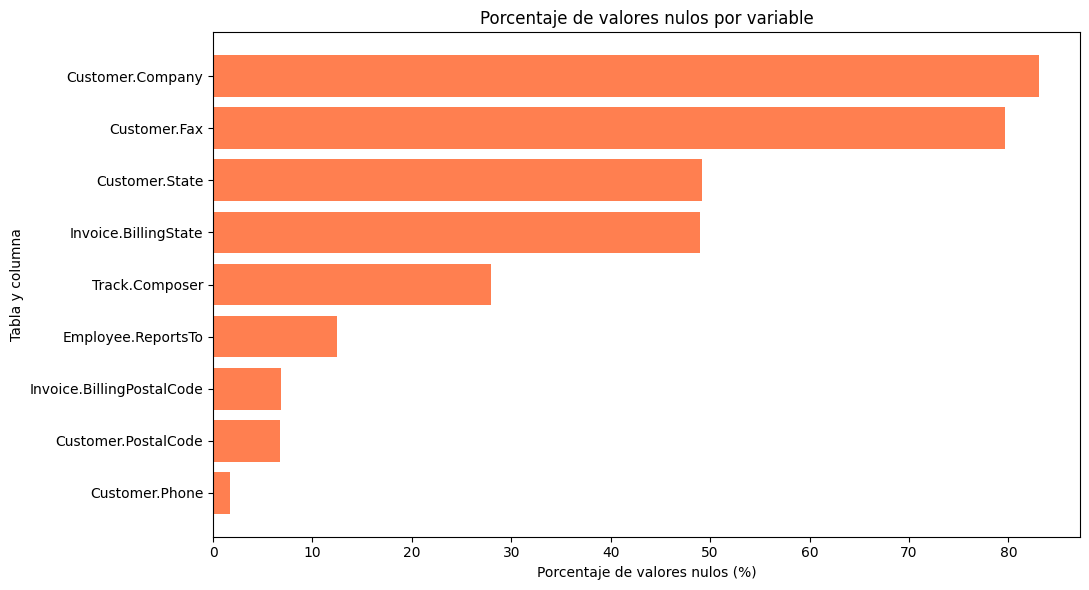

In [18]:

nulos_porcentaje = nulos_grafico.sort_values(
    "Porcentaje"
)

plt.figure(figsize=(11, 6))

plt.barh(
    nulos_porcentaje["Variable"],
    nulos_porcentaje["Porcentaje"],
    color="coral"
)

plt.title("Porcentaje de valores nulos por variable")
plt.xlabel("Porcentaje de valores nulos (%)")
plt.ylabel("Tabla y columna")

plt.tight_layout()
plt.show()


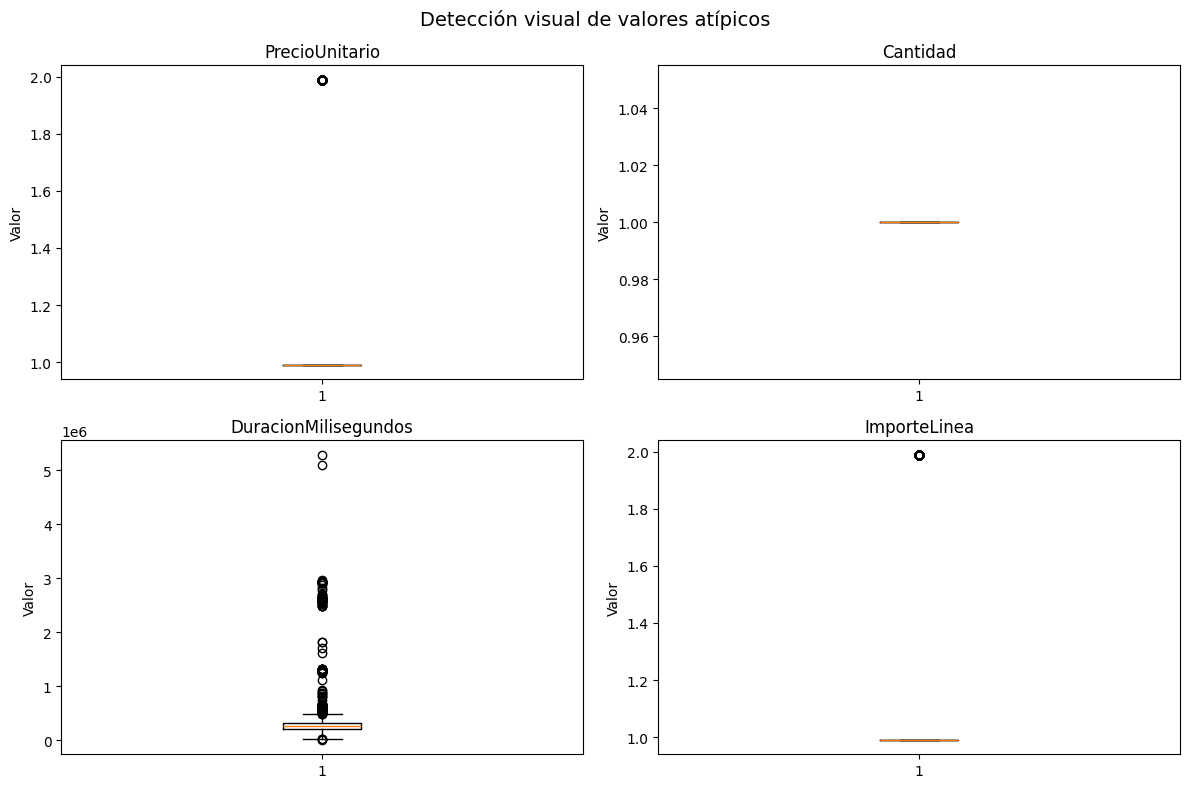

In [19]:

columnas_numericas = [
    "PrecioUnitario",
    "Cantidad",
    "DuracionMilisegundos",
    "ImporteLinea"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, columna in zip(axes.flat, columnas_numericas):
    ax.boxplot(
        ventas_tratadas[columna].dropna(),
        vert=True
    )

    ax.set_title(columna)
    ax.set_ylabel("Valor")

plt.suptitle(
    "Detección visual de valores atípicos",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [20]:

def detectar_atipicos_iqr(df, columna):
    datos = df[columna].dropna()

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = datos[
        (datos < limite_inferior) |
        (datos > limite_superior)
    ]

    return {
        "Variable": columna,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "LimiteInferior": limite_inferior,
        "LimiteSuperior": limite_superior,
        "Atipicos": len(atipicos),
        "Porcentaje": round(
            len(atipicos) / len(datos) * 100, 2
        )
    }


resultados_iqr = []

for columna in columnas_numericas:
    resultados_iqr.append(
        detectar_atipicos_iqr(
            ventas_tratadas, columna
        )
    )

resumen_atipicos = pd.DataFrame(resultados_iqr)

display(resumen_atipicos)


,Variable,Q1,Q3,IQR,LimiteInferior,LimiteSuperior,Atipicos,Porcentaje
0,PrecioUnitario,0.99,0.99,0.0,0.99,0.99,111,4.96
1,Cantidad,1.00,1.00,0.0,1.00,1.00,0,0.00
2,DuracionMilisegundos,205981.50,321136.00,115154.5,33249.75,493867.75,198,8.84
3,ImporteLinea,0.99,0.99,0.0,0.99,0.99,111,4.96


### Interpretación de los valores faltantes y atípicos

**Análisis de valores nulos**

Los gráficos permiten identificar las columnas de los archivos originales de Chinook que presentan información faltante, tanto en cantidades absolutas como en porcentajes. Esto facilita reconocer cuáles variables requieren mayor atención durante el tratamiento de datos.

Por otra parte, el conjunto analítico de ventas no presenta valores nulos, por lo que no fue necesario aplicar imputaciones adicionales sobre sus columnas.

**Análisis de valores atípicos**

Se utilizaron diagramas de caja (boxplots) y el método del rango intercuartílico (IQR) para analizar las variables numéricas del conjunto de ventas.

Los resultados permiten detectar observaciones que se encuentran fuera del comportamiento habitual de cada variable. Sin embargo, un valor atípico no necesariamente representa un error, ya que puede corresponder a una venta válida o a una canción con características diferentes.

Por este motivo, se decidió conservar los registros originales mientras no exista evidencia de que contienen información incorrecta. Esta decisión evita eliminar datos reales y mantiene la integridad del conjunto analítico para las siguientes etapas del laboratorio.